# Subject raw data: bound-vs-trial-number and step trajectories, all four blocks

Drill-down notebook for a single subject's raw data across all four canonical blocks
(1=Low fixed, 2=High fixed, 3=LowHigh CP, 4=HighLow CP). Set `SUBJECT` below and re-run.

Each block gets a side-by-side pair of panels:

1. **Left -- |bound| vs. trial number**, colored by pre-/post-change-point. For the two CP
   blocks (LowHigh, HighLow) this uses that block's own real, recorded change-point step. The two
   fixed blocks (Low, High) have no real change point, so they're split instead at the *associated*
   CP block's real change-point step (Low <-> LowHigh, High <-> HighLow) -- the "computed CP" --
   since `switch_time` is set by task design to approximate the subject's own median RT in the
   preceding fixed block (see the switch-timing note in the step-trajectory panel below).
2. **Right -- pigeon (accumulator) position vs. step index within trial**, one line per trial,
   colored the same way (orange=post, green=pre). Trials that extend past the reference step are
   drawn slightly thicker and darker so they stand out from the trials that ended before it. A
   vertical dashed line marks the reference step -- the real change point for CP blocks, or this
   block's own median RT for the fixed blocks.


In [1]:
import numpy as np
import matplotlib.pyplot as plt

from pigeon.stopping import get_stopping_model_trials

SUBJECT = 32   # <-- set the subject to examine here


In [2]:
# Canonical block-index -> name mapping and CP-block bookkeeping shared by every
# subject-level raw-data plot (Explore_subjectRawData.ipynb and its batch-PDF script).
RAW_DATA_BLOCK_NAMES = {1: 'Low', 2: 'High', 3: 'LowHigh', 4: 'HighLow'}
RAW_DATA_CP_BLOCKS = {3, 4}
RAW_DATA_CONTROL_ASSOC = {1: 3, 2: 4}   # fixed block -> associated CP block it's paired with


def _raw_data_get_steps(row):
    steps = row['steps']
    return steps[np.isfinite(steps)] if steps is not None else np.array([])


def _raw_data_correct_pm(correct):
    """+1 if correct==1, -1 if correct==0, NaN otherwise."""
    return np.where(correct == 1, 1.0, np.where(correct == 0, -1.0, np.nan))


def plot_subject_raw_grid(data_table, subject):
    """
    Plot one subject's raw bound-vs-trial and step-trajectory data, all four blocks.

    4 rows (Low, High, LowHigh, HighLow) x 2 columns: left is |bound| vs. trial number,
    right is the raw step (accumulator-position) trajectory vs. step index within trial.

    Both columns are re-signed relative to that trial's own correct/generative direction,
    not the fixed left/right screen convention `bound`/`steps` are stored in:

    - Left panel plots `abs_bound * correct_pm` (`correct_pm` = +1 if correct, -1 if error),
      so error trials plot as negative points.
    - Right panel re-signs each trial's raw `steps` trajectory by `sign(snr)` (the trial's
      own signed SNR, positive = right is the generative/correct side, stored in
      `data_table['snr']` before the `abs()` used internally for bound extraction), so
      positive always means "toward the correct/generative direction" for every trial.
      Endpoint markers are colored by the same correct/error split (blue=correct, red=error).

    Pre-/post-change-point coloring (orange/green) uses each block's own real change-point
    step for the two CP blocks (LowHigh, HighLow); the two fixed blocks (Low, High) have no
    real change point, so they're split instead at the *associated* CP block's real
    change-point step (Low <-> LowHigh, High <-> HighLow) -- the task sets `switch_time` to
    approximate the subject's own median RT in the preceding fixed block, so this is a
    synthetic-but-comparable split. Trials extending past the reference step are drawn
    thicker/darker on the right panel. Y-axes are shared across all four blocks per column;
    the step-trajectory column's x-axis (step index) is shared across all four blocks too, so
    trial lengths and shapes are directly comparable.

    Parameters
    ----------
    data_table : pandas.DataFrame
        Standard trial-level data table (e.g. from `get_data_table`), filtered as desired
        (e.g. `trial_number > 10`) before calling this function.
    subject : int or float
        Subject index to plot (matches `data_table['subject_index']`).

    Returns
    -------
    matplotlib.figure.Figure
        The created 4-row x 2-column figure. Caller is responsible for `plt.show()` /
        `savefig()` / `plt.close()` as appropriate.
    """
    sub = data_table[data_table['subject_index'] == subject].reset_index(drop=True)

    # ---- Shared y-axis ranges across all four blocks (signed, symmetric about 0) --------
    all_bound = sub['abs_bound'].to_numpy(dtype=float)
    all_bound = all_bound[np.isfinite(all_bound)]
    bound_max = np.nanmax(all_bound) * 1.05 if len(all_bound) else 1.0
    bound_ylim = (-bound_max, bound_max)

    step_vals = [s[np.isfinite(s)] for s in sub['steps'] if s is not None]
    step_vals = [s for s in step_vals if len(s)]
    if step_vals:
        step_max = np.max(np.abs(np.concatenate(step_vals))) * 1.05
        step_ylim = (-step_max, step_max)
    else:
        step_ylim = (-1, 1)

    # ---- Shared x-axis for the step-trajectory column across all four blocks ------------
    max_len = max((len(s) for s in step_vals), default=1)
    step_xlim = (-0.02 * max_len, max_len - 1 + 0.02 * max_len)

    fig, axs = plt.subplots(4, 2, figsize=(11, 15))

    for ri, bi in enumerate((1, 2, 3, 4)):
        blk = sub[sub['block_index'] == bi].reset_index(drop=True)
        name = RAW_DATA_BLOCK_NAMES[bi]
        ax_trial, ax_step = axs[ri, 0], axs[ri, 1]

        if len(blk) == 0:
            for ax in (ax_trial, ax_step):
                ax.set_title(f'{name}: no trials')
                ax.axis('off')
            continue

        rt = blk['RT'].to_numpy(dtype=float)
        trial_num = blk['trial_number'].to_numpy()
        abs_bound = blk['abs_bound'].to_numpy(dtype=float)
        correct = blk['correct'].to_numpy(dtype=float)
        correct_pm = _raw_data_correct_pm(correct)
        # Trial's own generative/correct direction sign (+1=right-correct, -1=left-correct),
        # kept signed in data_table['snr'] (only abs()'d internally for bound extraction).
        snr_sign = np.sign(blk['snr'].to_numpy(dtype=float))

        if bi in RAW_DATA_CP_BLOCKS:
            cp = blk['change_point'].to_numpy(dtype=float)
            valid_cp = cp[np.isfinite(cp) & (cp > 0)]
            ref = valid_cp[0] if len(valid_cp) else np.nan
            post = (cp > 0) & (rt > cp)
            step_line_label = f'change point (step {ref:.0f})' if np.isfinite(ref) else None
        else:
            assoc = sub[sub['block_index'] == RAW_DATA_CONTROL_ASSOC[bi]]
            assoc_cp = assoc['change_point'].to_numpy(dtype=float)
            valid_assoc_cp = assoc_cp[np.isfinite(assoc_cp) & (assoc_cp > 0)]
            ref = valid_assoc_cp[0] if len(valid_assoc_cp) else np.nan
            post = (rt > ref) if np.isfinite(ref) else np.zeros(len(blk), dtype=bool)
            med_rt_ctrl = np.nanmedian(rt)
            step_line_label = f'median RT ({med_rt_ctrl:.0f})' if np.isfinite(med_rt_ctrl) else None

        # ---- Left: signed |bound| (positive=correct, negative=error) vs. trial number,
        # colored pre/post ------------------------------------------------------------
        signed_bound = abs_bound * correct_pm
        colors = np.where(post, 'tab:orange', 'tab:green')
        order = np.argsort(trial_num)
        ax_trial.plot(trial_num[order], signed_bound[order], color='0.85', linewidth=0.8, zorder=1)
        ax_trial.scatter(trial_num, signed_bound, c=colors, s=14, zorder=2, edgecolor='none')
        ax_trial.axhline(0, color='0.7', linewidth=0.8, zorder=0)
        ax_trial.set_ylim(bound_ylim)
        ax_trial.set_xlabel('Trial number')
        ax_trial.set_ylabel('|bound| (+correct / -error)')
        cp_kind = 'real CP' if bi in RAW_DATA_CP_BLOCKS else 'computed CP (assoc. block)'
        ax_trial.set_title(f'Subject {subject}: {name} (n={len(blk)})\n'
                            f'orange=post-{cp_kind}, green=pre')
        ax_trial.spines['top'].set_visible(False)
        ax_trial.spines['right'].set_visible(False)

        # ---- Right: step trajectories re-signed to +correct/-error, thicker/darker
        # past the reference step, shared x-axis across blocks -------------------------
        for ii in range(len(blk)):
            steps = _raw_data_get_steps(blk.iloc[ii])
            if len(steps) == 0 or snr_sign[ii] == 0 or not np.isfinite(snr_sign[ii]):
                continue
            resigned_steps = steps * snr_sign[ii]
            is_post = bool(post[ii])
            color = 'tab:orange' if is_post else 'tab:green'
            lw = 1.2 if is_post else 0.7
            alpha = 0.45 if is_post else 0.22
            ax_step.plot(np.arange(len(resigned_steps)), resigned_steps, color=color, alpha=alpha,
                         linewidth=lw, zorder=2 if is_post else 1)
            end_color = 'tab:blue' if correct_pm[ii] > 0 else 'tab:red'
            ax_step.plot(len(resigned_steps) - 1, resigned_steps[-1], 'o', color=end_color,
                         markersize=3, alpha=0.6, zorder=3)

        line_ref = ref if bi in RAW_DATA_CP_BLOCKS else med_rt_ctrl
        if step_line_label is not None:
            ax_step.axvline(line_ref, color='k', linestyle='--', linewidth=1, zorder=0,
                            label=step_line_label)
            ax_step.legend(loc='upper right', fontsize=8, frameon=False)
        ax_step.axhline(0, color='0.7', linewidth=0.8, zorder=0)
        ax_step.set_ylim(step_ylim)
        ax_step.set_xlim(step_xlim)
        ax_step.set_xlabel('Step index within trial')
        ax_step.set_ylabel('Accumulator position (+correct / -error)')
        ax_step.set_title(f'Subject {subject}: {name} (n={len(blk)})')
        ax_step.spines['top'].set_visible(False)
        ax_step.spines['right'].set_visible(False)

    plt.tight_layout()
    return fig


## Load data

The trials `Figure06_cpSummary.ipynb` uses (`get_stopping_model_trials`: trial_number ≥ 10, with a
recorded choice; raw bounds, no bias correction), so subject-level quantities here match that
notebook exactly.


In [3]:
data_table_mxsc = get_stopping_model_trials('MXSC', [1, 2, 3, 4]).reset_index(drop=True)

print(f'Subject {SUBJECT}: '
      f'{int((data_table_mxsc["subject_index"] == SUBJECT).sum())} trials (all blocks, trial_number >= 10, with a choice)')


MXSC: 30,214 trials in blocks [1, 2, 3, 4]; excluded 2,214 with trial_number < 10, 236 more with no choice; 65 subjects
Subject 32: 531 trials (all blocks, trial_number >= 10, with a choice)


## Raw bound-vs-trial and step trajectories, all four blocks

4 rows (Low, High, LowHigh, HighLow) x 2 columns (bound vs. trial number | step trajectories),
via `plot_subject_raw_grid` (defined above).

Both columns are re-signed relative to that trial's own correct/generative direction, not the
fixed left/right screen convention `bound`/`steps` are stored in (`bound`'s and `steps`' sign just
tracks which physical side the response ended up on).

- Left panel plots `abs_bound * correct_pm` (`correct_pm` = +1 if the trial's `correct` column is
  1, -1 if 0), so error trials show up as negative points -- positive = correct, negative = error.
- Right panel re-signs each trial's raw `steps` trajectory by `sign(snr)`, the trial's own signed
  SNR (positive = right is the generative/correct side, negative = left is), stored in
  `data_table['snr']` before the `abs()` used internally for bound extraction. Multiplying by this
  per-trial sign means positive on this panel always means "toward the correct/generative
  direction," for every trial, regardless of which physical side that was. A trial's raw endpoint
  always lands on the side it chose, so a resigned trajectory that ends up positive is a trial that
  chose correctly, and one that ends up negative chose the error side -- consistent with the left
  panel's sign. Endpoint markers are colored by the same correct/error split (blue=correct,
  red=error) instead of by raw left/right choice.

Both the bound scale (left column) and the step-position scale (right column) are shared across
all four blocks; the step-trajectory column's x-axis (step index within trial) is shared across
all four blocks too, so trial lengths are directly comparable.


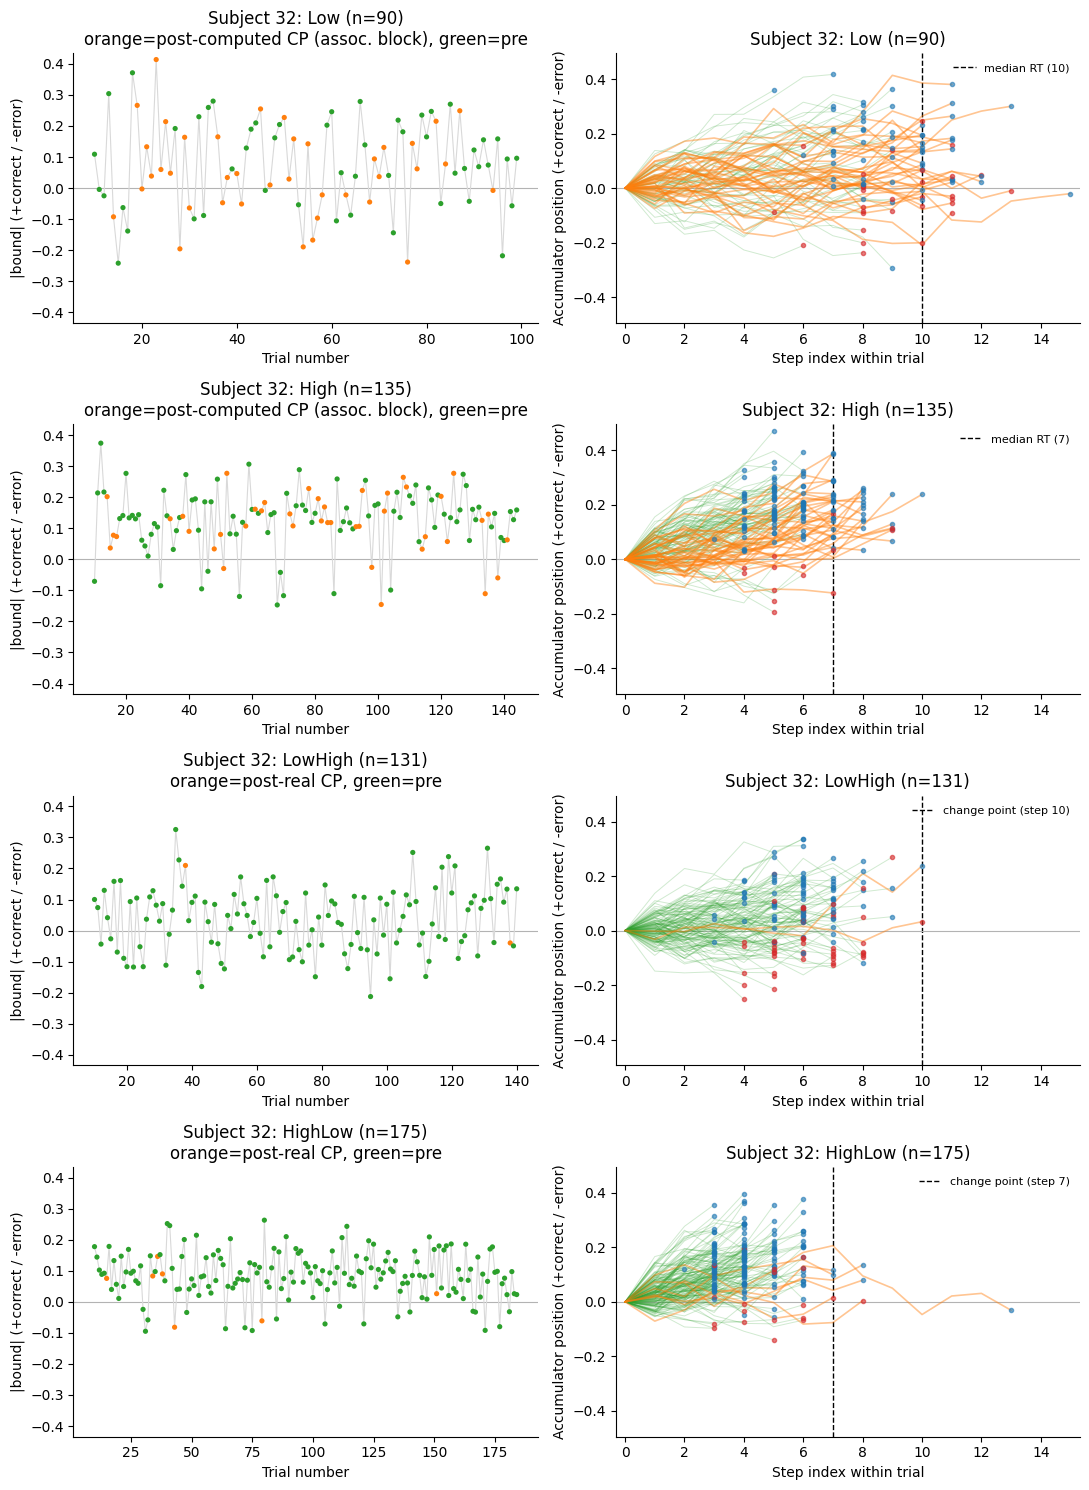

In [4]:
fig = plot_subject_raw_grid(data_table_mxsc, SUBJECT)
plt.show()
